# Agentic Example: Gemini + Claude Workflows
This notebook groups LLM and agentic examples extracted from the original notebook.

In [11]:
import os
import io
import base64
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from fastai.data.transforms import get_image_files
import sys
from pathlib import Path
sys.path.insert(0, str(Path('/home/axt807/ivory_project/github_repo/src').resolve()))
from ivory_repo.llm import init_gemini_client, init_anthropic_client, gemini_classify_image

### Agentic model configuration:

In [ ]:
# Set once per kernel session, or export in your shell before launching Jupyter
# os.environ['GOOGLE_API_KEY'] = '...'; os.environ['ANTHROPIC_API_KEY'] = '...'
os.environ["GOOGLE_API_KEY"] = "..."
os.environ["ANTHROPIC_API_KEY"] = "..."
gemini_client = init_gemini_client()
claude_client = init_anthropic_client()
model_id = 'gemini-2.5-flash'

### Ivory/bone image analysis:

Selected: A_Tusk_Figurine_of_a_Man_MET_DP237714.jpeg


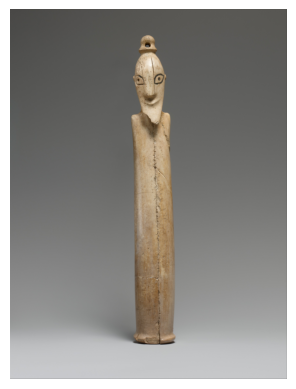

In [27]:
test_path = Path('/mnt/vstor/CAS_PHY_GDS6/axt807/data/Ivory_data/Ivory/Public_domain_ivory_bone_images/ivory')
image_files = get_image_files(test_path)
image_path = image_files[0]
print('Selected:', image_path.name)

## Plot the image:
img = Image.open(image_path)
plt.imshow(img)
plt.axis('off')
plt.show()

In [14]:
# Gemini classification helper
result = gemini_classify_image(gemini_client, model_id, image_path)
result

{'class': 'bone',
 'confidence': 0.8,
 'reasoning': 'The object displays prominent parallel longitudinal striations and cracks running along its length, which is characteristic of the fibrous and lamellar structure found in carved bone. There is no visible evidence of Schreger lines, which are a diagnostic feature for identifying elephant ivory on transverse or diagonal cuts. The overall opaque appearance and grain pattern are more consistent with bone.',
 'raw_text': '```json\n{\n  "class": "bone",\n  "confidence": 0.8,\n  "reasoning": "The object displays prominent parallel longitudinal striations and cracks running along its length, which is characteristic of the fibrous and lamellar structure found in carved bone. There is no visible evidence of Schreger lines, which are a diagnostic feature for identifying elephant ivory on transverse or diagonal cuts. The overall opaque appearance and grain pattern are more consistent with bone."\n}\n```'}

In [15]:
# Claude vision call example from the original workflow
image = Image.open(image_path).convert('RGB')
buf = io.BytesIO()
image.save(buf, format='PNG')
image_base64 = base64.b64encode(buf.getvalue()).decode('utf-8')

message = claude_client.messages.create(
    model='claude-opus-4-1-20250805',
    max_tokens=512,
    messages=[
        {
            'role': 'user',
            'content': [
                {
                    'type': 'image',
                    'source': {
                        'type': 'base64',
                        'media_type': 'image/png',
                        'data': image_base64,
                    },
                },
                {
                    'type': 'text',
                    'text': 'Describe this image in detail and assess whether material evidence suggests ivory, bone, or uncertain.'
                },
            ],
        }
    ],
)
print(message.content[0].text)

This is an elongated cylindrical figure with a carved head and minimal body definition. The figure features a stylized face with simple circular eyes, a vertical ridge for the nose, and what appears to be a slight smile. The head is crowned with a small knob or topknot with a hole through it, possibly for suspension or attachment.

The body is essentially a long, smooth cylinder that tapers slightly, with a visible vertical crack or seam running down the center of the front. This crack appears to be a natural split in the material rather than an intentional decorative element.

**Material Assessment:**

Several features suggest this is likely **bone** rather than ivory:

1. **Color and patina**: The piece displays a matte, slightly yellowed surface typical of aged bone, lacking the lustrous quality often associated with ivory.

2. **Structural crack**: The long vertical crack down the center is characteristic of bone, which tends to split along its natural grain structure. Ivory typica

### Gemini batch classification over multiple images
This cell uses the existing Gemini helper to classify a small set of test images as ivory, bone, or uncertain.

In [16]:
# Run Gemini classification on a few sample images from test_path
for image_path in image_files[:4]:
    result = gemini_classify_image(gemini_client, model_id, image_path)
    print(f"{image_path.name}: {result['class']} (confidence={result.get('confidence')})")
    print(result.get('reasoning', 'No reasoning returned'))
    print('-'*80)

A_Tusk_Figurine_of_a_Man_MET_DP237714.jpeg: ivory (confidence=0.85)
The object displays distinct, fine longitudinal striations and growth lines along its length. These parallel lines, consistent with the directional growth of a tusk, are a strong indicator of ivory. There is no visible evidence of the porous, cancellous structure or Haversian systems typically seen in bone.
--------------------------------------------------------------------------------
Ashinaga_and_Tenaga_with_Octopus,_Japan,_19th_century,_ivory_and_sumi_-_Chazen_Museum_of_Art_-_DSC01722.jpeg: ivory (confidence=0.75)
The material exhibits a smooth, dense, and uniform texture across its surface. There are no visible pores or Haversian systems, which are characteristic features of carved bone. While Schreger lines are not clearly discernible in this three-dimensional carving, the overall appearance is consistent with aged ivory.
--------------------------------------------------------------------------------
Beauty_stat

### Gemini direct segmentation mask generation
This example asks Gemini to return a structured JSON description of a main object, including a polygon mask.

In [20]:
import json
from PIL import ImageDraw

seg_image_path = image_files[0]
seg_image = Image.open(seg_image_path).convert("RGB")
buf = io.BytesIO()
seg_image.save(buf, format="PNG")
seg_bytes = buf.getvalue()

response = gemini_client.models.generate_content(
    model=model_id,
    contents=[
        {
            "parts": [
                {
                    "inline_data": {
                        "mime_type": "image/png",
                        "data": seg_bytes,
                    }
                },
                {
                    "text": (
                        "Detect the main object in this image and return ONLY a JSON "
                        "object with keys: label, box_2d, polygon. "
                        "Use normalized coordinates in a 0-1000 scale for box_2d "
                        "and polygon coordinates."
                    )
                },
            ]
        }
    ],
)

try:
    seg_data = json.loads(response.text)
    print("Gemini segmentation result:")
    print(json.dumps(seg_data, indent=2))
except json.JSONDecodeError:
    print("Failed to parse Gemini response as JSON:")
    print(response.text)

Failed to parse Gemini response as JSON:
```json
{
  "label": "main object",
  "box_2d": [63, 442, 908, 597],
  "polygon": "[[63, 471], [70, 483], [79, 497], [85, 510], [94, 519], [103, 523], [109, 519], [116, 506], [120, 490], [121, 476], [120, 467], [129, 461], [137, 458], [150, 455], [163, 451], [180, 448], [199, 447], [214, 448], [225, 453], [225, 464], [220, 471], [214, 477], [206, 483], [198, 487], [188, 488], [178, 488], [166, 487], [154, 486], [140, 486], [128, 486], [120, 487], [114, 489], [109, 492], [107, 497], [106, 502], [108, 506], [109, 510], [113, 513], [116, 514], [119, 514], [123, 512], [128, 509], [132, 506], [136, 503], [140, 501], [143, 500], [146, 500], [149, 501], [152, 502], [154, 504], [157, 505], [160, 507], [162, 508], [163, 510], [164, 511], [164, 512], [163, 513], [161, 514], [159, 516], [156, 518], [152, 520], [149, 522], [146, 523], [142, 524], [138, 524], [134, 523], [130, 521], [126, 519], [122, 517], [119, 514], [118, 510], [119, 506], [120, 502], [122

### Claude segmentation description
This agentic example asks Claude to describe the object location and boundaries in detail, suitable for segmentation guidance.

In [21]:
image_message = {
    'type': 'image',
    'source': {
        'type': 'base64',
        'media_type': 'image/png',
        'data': image_base64,
    },
}

message_segmentation = claude_client.messages.create(
    model='claude-opus-4-1-20250805',
    max_tokens=2048,
    messages=[
        {
            'role': 'user',
            'content': [
                image_message,
                {
                    'type': 'text',
                    'text': (
                        'Analyze this image to identify the main object, '
                        'determining whether it is made of ivory or bone. '
                        'Provide a very detailed description of its precise location '
                        '(for example, top-left quadrant, center, spanning X to Y coordinates, or filling approximately N% of the image), '
                        'its shape, its boundaries, and the features that distinguish it from the background. '
                        'Describe which parts are definitely object and which are background, '
                        'as if you were preparing instructions for someone to draw a pixel-accurate segmentation mask.'
                    )
                }
            ],
        }
    ],
)

print(message_segmentation.content[0].text)


The main object in this image is a carved figurine made of ivory or bone, positioned centrally against a neutral gray gradient background. The figurine occupies approximately 70-80% of the image height, extending from near the top to near the bottom of the frame.

**Precise Location and Boundaries:**
- The figurine spans vertically from approximately 10% from the top edge to about 95% down the image
- Horizontally, it's centered, occupying roughly the middle 20-25% of the image width
- The object creates a clear silhouette against the gradient background

**Shape and Features:**
The figurine has a distinctive elongated form with:
- **Head/Top portion** (upper 20%): Features a stylized face with visible eyes, nose, and mouth, topped with what appears to be a small knob or topknot with a hole through it
- **Neck region** (next 5%): A narrower transition between head and body
- **Body/Column** (remaining 75%): A long, cylindrical or slightly tapered column form with a visible vertical cra

### Claude bounding-box JSON extraction
This example asks Claude to return only a JSON object with the main object bounding box, using normalized coordinates.

In [22]:
image_message = {
    'type': 'image',
    'source': {
        'type': 'base64',
        'media_type': 'image/png',
        'data': image_base64,
    },
}

message_box = claude_client.messages.create(
    model='claude-opus-4-5',
    max_tokens=512,
    messages=[
        {
            'role': 'user',
            'content': [
                image_message,
                {
                    'type': 'text',
                    'text': (
                        'Find the main object of interest in this image and return ONLY a JSON object with the normalized bounding box, like: ' +
                        '{"label": "object", "x_min": 0.1, "y_min": 0.2, "x_max": 0.8, "y_max": 0.9}. ' +
                        'Do not add any surrounding text or explanation.'
                    )
                }
            ]
        }
    ]
)

raw_box = message_box.content[0].text.strip()
print(raw_box)


{"label": "ivory figurine", "x_min": 0.38, "y_min": 0.08, "x_max": 0.62, "y_max": 0.95}


### Improved Claude approache: 

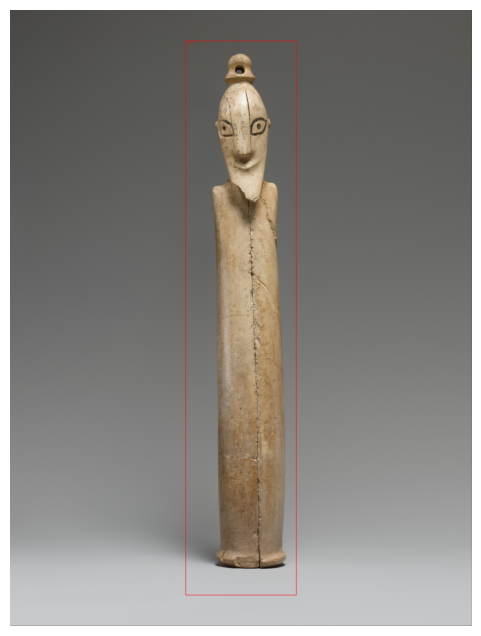

Detected objects: ['ivory figurine']


In [28]:
import json
import re
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Load the exact image file used for the Claude request
image = Image.open(image_path).convert("RGB")

buf = io.BytesIO()
image.save(buf, format="PNG")
image_base64 = base64.b64encode(buf.getvalue()).decode("utf-8")

image_message = {
    "type": "image",
    "source": {
        "type": "base64",
        "media_type": "image/png",
        "data": image_base64,
    },
}

prompt = """Find all main objects of interest in this image.
Return ONLY valid JSON: a list of objects, each with
  "label", "x_min", "y_min", "x_max", "y_max".
Coordinates must be normalized 0.0 to 1.0 relative to image width and height.
Example:
[
  {"label": "object name", "x_min": 0.1, "y_min": 0.2, "x_max": 0.8, "y_max": 0.9},
  {"label": "another object", "x_min": 0.2, "y_min": 0.3, "x_max": 0.5, "y_max": 0.7}
]
If there are multiple objects, return all of them.
Do not include any markdown, explanation, or extra text."""
message_box = claude_client.messages.create(
    model="claude-opus-4-5",
    max_tokens=1024,
    messages=[
        {
            "role": "user",
            "content": [
                image_message,
                {"type": "text", "text": prompt},
            ],
        }
    ],
)

raw_text = message_box.content[0].text.strip()
raw_text = re.sub(r"^```json|^```|```$", "", raw_text, flags=re.MULTILINE).strip()
results = json.loads(raw_text)

if isinstance(results, dict):
    results = [results]

draw_img = image.copy()
draw = ImageDraw.Draw(draw_img)
w, h = draw_img.size

for item in results:
    x0 = item["x_min"] * w
    y0 = item["y_min"] * h
    x1 = item["x_max"] * w
    y1 = item["y_max"] * h
    draw.rectangle([x0, y0, x1, y1], outline="red", width=3)
    draw.text((x0 + 4, y0 + 4), item.get("label", "object"), fill="red")

plt.figure(figsize=(8, 8))
plt.imshow(draw_img)
plt.axis("off")
plt.show()

print("Detected objects:", [item.get("label") for item in results])